# Student Assignment: Sales Data Analysis - Complete Solution

This notebook provides a comprehensive solution for analyzing sales data using Python and Pandas. The assignment covers data creation, exploration, cleaning, analysis, visualization, and reporting.

## Assignment Overview

**Objective**: Analyze sales data to derive business insights and recommendations

**Skills Demonstrated**:
- Data generation and simulation
- Data exploration and cleaning
- Statistical analysis and aggregations
- Data visualization
- Business reporting and insights

**Tools Used**: Python, Pandas, NumPy, Matplotlib, Seaborn

In [8]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

SAMPLE_DAT_DIR = 'data/sample_sales_data.csv'

Libraries imported successfully!


## Part 1: Create Sample Sales Dataset

First, we'll create a realistic sample dataset to work with. This simulates a real-world scenario where you need to work with sales data.

In [9]:
print("=== CREATING SAMPLE SALES DATASET ===")

# Set random seed for reproducibility
np.random.seed(42)

# Generate sample sales data
n_orders = 2500

# Product categories and names
categories = ['Electronics', 'Clothing', 'Books', 'Home & Garden', 'Sports', 'Beauty', 'Toys']
electronics = ['Laptop', 'Smartphone', 'Tablet', 'Headphones', 'Camera']
clothing = ['T-Shirt', 'Jeans', 'Dress', 'Jacket', 'Shoes']
books = ['Fiction Novel', 'Textbook', 'Biography', 'Cookbook', 'Self-Help']
home_garden = ['Plant Pot', 'Garden Tools', 'Furniture', 'Decorative Item', 'Kitchen Appliance']
sports = ['Running Shoes', 'Yoga Mat', 'Dumbbell', 'Tennis Racket', 'Bicycle']
beauty = ['Moisturizer', 'Lipstick', 'Shampoo', 'Perfume', 'Face Mask']
toys = ['Board Game', 'Action Figure', 'Puzzle', 'Building Blocks', 'Doll']

product_dict = {
    'Electronics': electronics,
    'Clothing': clothing,
    'Books': books,
    'Home & Garden': home_garden,
    'Sports': sports,
    'Beauty': beauty,
    'Toys': toys
}

# Generate customer names
first_names = ['John', 'Jane', 'Michael', 'Sarah', 'David', 'Emily', 'Robert', 'Lisa', 'William', 'Ashley',
               'James', 'Jessica', 'Christopher', 'Amanda', 'Daniel', 'Melissa', 'Matthew', 'Deborah', 
               'Anthony', 'Dorothy', 'Mark', 'Nancy', 'Donald', 'Karen', 'Steven', 'Betty', 'Kenneth', 'Helen']
last_names = ['Smith', 'Johnson', 'Williams', 'Brown', 'Jones', 'Garcia', 'Miller', 'Davis', 'Rodriguez', 
              'Martinez', 'Hernandez', 'Lopez', 'Gonzalez', 'Wilson', 'Anderson', 'Thomas', 'Taylor', 'Moore']

print("Dataset configuration completed!")

=== CREATING SAMPLE SALES DATASET ===
Dataset configuration completed!


In [10]:
# Create the dataset
sales_data = []

for i in range(n_orders):
    # Basic order info
    order_id = f"ORD-{i+1:06d}"
    customer_id = f"CUST-{np.random.randint(1, 800):05d}"
    
    # Customer name
    first_name = np.random.choice(first_names)
    last_name = np.random.choice(last_names)
    customer_name = f"{first_name} {last_name}"
    
    # Product selection
    category = np.random.choice(categories)
    product_name = np.random.choice(product_dict[category])
    
    # Order details
    quantity = np.random.randint(1, 5)
    
    # Unit price varies by category
    if category == 'Electronics':
        unit_price = np.round(np.random.uniform(50, 1500), 2)
    elif category == 'Clothing':
        unit_price = np.round(np.random.uniform(15, 200), 2)
    elif category == 'Books':
        unit_price = np.round(np.random.uniform(10, 50), 2)
    elif category == 'Home & Garden':
        unit_price = np.round(np.random.uniform(20, 300), 2)
    elif category == 'Sports':
        unit_price = np.round(np.random.uniform(25, 500), 2)
    elif category == 'Beauty':
        unit_price = np.round(np.random.uniform(10, 100), 2)
    else:  # Toys
        unit_price = np.round(np.random.uniform(15, 150), 2)
    
    total_amount = quantity * unit_price
    
    # Order date (2023 data)
    start_date = datetime(2023, 1, 1)
    end_date = datetime(2023, 12, 31)
    order_date = start_date + timedelta(days=np.random.randint(0, (end_date - start_date).days))
    
    # Customer segment
    customer_segment = np.random.choice(['Business', 'Individual'], p=[0.3, 0.7])
    
    # Region
    region = np.random.choice(['North', 'South', 'East', 'West', 'Central'])
    
    # Shipping cost
    if total_amount > 100:
        shipping_cost = 0  # Free shipping for orders over $100
    else:
        shipping_cost = np.round(np.random.uniform(5, 15), 2)
    
    sales_data.append({
        'order_id': order_id,
        'customer_id': customer_id,
        'customer_name': customer_name,
        'product_category': category,
        'product_name': product_name,
        'quantity': quantity,
        'unit_price': unit_price,
        'total_amount': total_amount,
        'order_date': order_date.strftime('%Y-%m-%d'),
        'customer_segment': customer_segment,
        'region': region,
        'shipping_cost': shipping_cost
    })

print(f"Generated {len(sales_data)} sales records!")

Generated 2500 sales records!


In [25]:
# Create DataFrame
df_sales = pd.DataFrame(sales_data)

# Add some missing values to make it realistic
missing_indices = np.random.choice(df_sales.index, size=100, replace=False)
df_sales.loc[missing_indices[:50], 'shipping_cost'] = np.nan
df_sales.loc[missing_indices[50:], 'customer_segment'] = np.nan

# Save the dataset
df_sales.to_csv(SAMPLE_DAT_DIR, index=False)
print(f"Sample sales dataset created with {len(df_sales)} orders")
print(f"Dataset saved as '{SAMPLE_DAT_DIR}'")
print("\nFirst 5 rows of the dataset:")
print(df_sales.head())

Sample sales dataset created with 2500 orders
Dataset saved as 'data/sample_sales_data.csv'

First 5 rows of the dataset:
     order_id customer_id     customer_name product_category  product_name  \
0  ORD-000001  CUST-00103  Dorothy Anderson            Books     Self-Help   
1  ORD-000002  CUST-00664   Michael Johnson    Home & Garden  Garden Tools   
2  ORD-000003  CUST-00748     Steven Taylor            Books     Biography   
3  ORD-000004  CUST-00244   Steven Williams           Sports      Dumbbell   
4  ORD-000005  CUST-00316      Amanda Moore         Clothing       T-Shirt   

   quantity  unit_price  total_amount  order_date customer_segment   region  \
0         1       16.24         16.24  2023-08-03         Business  Central   
1         4      297.82       1191.28  2023-06-10       Individual  Central   
2         3       15.58         46.74  2023-07-07       Individual     East   
3         3      106.00        318.00  2023-06-16         Business    North   
4         2   

## Part 2: Assignment Solution

Now we'll work through the complete assignment solution, analyzing the sales data step by step.

### Task 1: Data Exploration

Let's start by exploring our dataset to understand its structure and characteristics.

In [26]:
print("=== TASK 1: DATA EXPLORATION ===")

# Load the data
df = pd.read_csv(SAMPLE_DAT_DIR)

=== TASK 1: DATA EXPLORATION ===


In [27]:
# overview
df.info()

# first 20 rows
print("\nFirst 20 rows of the dataset:")
display(df.head(20))

# describe
print("\nDescriptive statistics of the dataset:")
display(df.describe(include='all'))

# show cols contain missing values
print("\nColumns with missing values:")
missing_values = df.isna().sum()
display(missing_values[missing_values > 0].to_frame())

# check duplication
print(f"duplicate rows: {df.duplicated().sum()}")
print(f"duplicate order IDs: {df['order_id'].duplicated().sum()}")




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          2500 non-null   object 
 1   customer_id       2500 non-null   object 
 2   customer_name     2500 non-null   object 
 3   product_category  2500 non-null   object 
 4   product_name      2500 non-null   object 
 5   quantity          2500 non-null   int64  
 6   unit_price        2500 non-null   float64
 7   total_amount      2500 non-null   float64
 8   order_date        2500 non-null   object 
 9   customer_segment  2450 non-null   object 
 10  region            2500 non-null   object 
 11  shipping_cost     2450 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 234.5+ KB

First 20 rows of the dataset:


,order_id,customer_id,customer_name,product_category,product_name,quantity,unit_price,total_amount,order_date,customer_segment,region,shipping_cost
0,ORD-000001,CUST-00103,Dorothy Anderson,Books,Self-Help,1,16.24,16.24,2023-08-03,Business,Central,11.01
1,ORD-000002,CUST-00664,Michael Johnson,Home & Garden,Garden Tools,4,297.82,1191.28,2023-06-10,Individual,Central,0.00
2,ORD-000003,CUST-00748,Steven Taylor,Books,Biography,3,15.58,46.74,2023-07-07,Individual,East,8.82
3,ORD-000004,CUST-00244,Steven Williams,Sports,Dumbbell,3,106.00,318.00,2023-06-16,Business,North,0.00
4,ORD-000005,CUST-00316,Amanda Moore,Clothing,T-Shirt,2,33.07,66.14,2023-12-06,Business,West,6.22
5,ORD-000006,CUST-00509,Lisa Anderson,Books,Fiction Novel,4,17.29,69.16,2023-01-02,NaN,South,10.68
6,ORD-000007,CUST-00477,Deborah Lopez,Clothing,Jeans,2,186.43,372.86,2023-12-17,NaN,West,0.00
7,ORD-000008,CUST-00702,Lisa Thomas,Sports,Yoga Mat,3,418.65,1255.95,2023-08-05,Business,West,0.00
8,ORD-000009,CUST-00493,William Anderson,Sports,Running Shoes,1,493.77,493.77,2023-12-10,Individual,East,0.00
9,ORD-000010,CUST-00499,Matthew Davis,Books,Biography,1,34.24,34.24,2023-08-19,Individual,West,13.63



Descriptive statistics of the dataset:


,order_id,customer_id,customer_name,product_category,product_name,quantity,unit_price,total_amount,order_date,customer_segment,region,shipping_cost
count,2500,2500,2500,2500,2500,2500.000000,2500.000000,2500.000000,2500,2450,2500,2450.000000
unique,2500,764,502,7,35,NaN,NaN,NaN,363,2,5,NaN
top,ORD-000001,CUST-00111,Steven Anderson,Books,Fiction Novel,NaN,NaN,NaN,2023-06-22,Individual,West,NaN
freq,1,9,12,392,95,NaN,NaN,NaN,15,1726,529,NaN
mean,NaN,NaN,NaN,NaN,NaN,2.438400,206.638660,504.621608,NaN,NaN,NaN,2.764159
std,NaN,NaN,NaN,NaN,NaN,1.115125,294.342232,817.788698,NaN,NaN,NaN,4.721066
min,NaN,NaN,NaN,NaN,NaN,1.000000,10.060000,10.060000,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,1.000000,43.905000,92.017500,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,2.000000,97.640000,213.620000,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,3.000000,212.352500,514.515000,NaN,NaN,NaN,5.890000



Columns with missing values:


,0
customer_segment,50
shipping_cost,50


duplicate rows: 0
duplicate order IDs: 0


chuyen order_date tu object -> datetime

customer_segment thieu 50 values -> fill "Unknown"

shipping_cost thieu 50 values -> fill median

khong co duplicate

### Task 2: Data Cleaning

Before analysis, we need to clean our data by handling missing values and ensuring proper data types.

In [28]:
print("=== TASK 2: DATA CLEANING ===")
print("rows before cleaning:", len(df))

# convert date format
df['order_date'] = pd.to_datetime(df['order_date'], format='%Y-%m-%d')

# Fill unknown for missing customer segments
df['customer_segment'] = df['customer_segment'].fillna('Unknown')

print("missing values after cleaning:")
print(df.isna().sum()[lambda x: x > 0])
print(f'\norder_date type: {df["order_date"].dtype}')

print("rows after cleaning:", len(df))



=== TASK 2: DATA CLEANING ===
rows before cleaning: 2500
missing values after cleaning:
shipping_cost    50
dtype: int64

order_date type: datetime64[ns]
rows after cleaning: 2500


### Task 3: Sales Analysis

Now let's perform comprehensive sales analysis to understand revenue patterns, customer behavior, and trends.

In [29]:
print("=== TASK 3: SALES ANALYSIS ===")

# OVERVIEW
# revenue
total_revenue = df['total_amount'].sum()

# number of unique orders
total_orders = df['order_id'].nunique()

# quantity
total_units = df['quantity'].sum()

# average order value
average_order_value = total_revenue / total_orders

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Units Sold: {total_units}")
print(f"Average Order Value: ${average_order_value:,.2f}")

=== TASK 3: SALES ANALYSIS ===
Total Revenue: $1,261,554.02
Total Orders: 2500
Total Units Sold: 6096
Average Order Value: $504.62


In [30]:
# SALE ANALYSIS BY CATEGORY
# group by product category
category_sales = df.groupby("product_category", as_index=False).agg(
    total_revenue=("total_amount", "sum"),
    total_orders=("order_id", "nunique"),
    total_units=("quantity", "sum"),
)

# avg order value by category
category_sales['average_order_value'] = category_sales['total_revenue'] / category_sales['total_orders']

# revenue of category / total revenue
category_sales['revenue_share_pct'] = category_sales['total_revenue'] / total_revenue * 100

# desc sort by revenue
category_sales = category_sales.sort_values('total_revenue', ascending=False)

display(category_sales.round({
    'total_revenue': 2,
    'average_order_value': 2,
    'revenue_share_pct': 2
}))

,product_category,total_revenue,total_orders,total_units,average_order_value,revenue_share_pct
3,Electronics,657136.57,364,882,1805.32,52.09
5,Sports,214606.40,326,822,658.30,17.01
4,Home & Garden,147937.67,365,907,405.31,11.73
2,Clothing,100490.14,368,911,273.07,7.97
6,Toys,68144.08,354,823,192.50,5.40
0,Beauty,45626.46,331,826,137.84,3.62
1,Books,27612.70,392,925,70.44,2.19


In [31]:
# SALE ANALYSIS BY PRODUCT
product_performance = (
    df.groupby('product_name', as_index=False)
      .agg(
          total_revenue=('total_amount', 'sum'),
          total_orders=('order_id', 'nunique'),
          total_units=('quantity', 'sum'),
          average_unit_price=('unit_price', 'mean')
      )
)

# revenue share percentage
product_performance['revenue_share_pct'] = (
    product_performance['total_revenue']
    / total_revenue
    * 100
)

# sort by total revenue
product_performance = product_performance.sort_values(
    'total_revenue',
    ascending=False
)

# top 10 products by revenue
display(
    product_performance.head(10).round({
        'total_revenue': 2,
        'average_unit_price': 2,
        'revenue_share_pct': 2
    })
)

,product_name,total_revenue,total_orders,total_units,average_unit_price,revenue_share_pct
19,Laptop,153964.37,75,190,798.90,12.20
29,Smartphone,142789.72,84,203,740.03,11.32
15,Headphones,136806.83,82,192,731.66,10.84
31,Tablet,112972.75,62,151,715.64,8.96
5,Camera,110602.90,61,146,731.30,8.77
10,Dumbbell,46823.67,72,188,254.90,3.71
34,Yoga Mat,46438.60,75,183,267.77,3.68
1,Bicycle,42443.81,58,145,296.01,3.36
32,Tennis Racket,40583.18,65,169,239.76,3.22
25,Running Shoes,38317.14,56,137,275.03,3.04


In [32]:
# SALE ANALYSIS BY MONTH

# order_month
df['order_month'] = df['order_date'].dt.to_period('M')

# group by month
monthly_sales = df.groupby('order_month', as_index=False).agg(
    total_revenue=('total_amount', 'sum'),
    total_orders=('order_id', 'nunique'),
    total_units=('quantity', 'sum')
)

# avg order value by month
monthly_sales['average_order_value'] = monthly_sales['total_revenue'] / monthly_sales['total_orders']

# cur_month / last_month revenue growth
monthly_sales['revenue_growth_pct'] = monthly_sales['total_revenue'].pct_change() * 100

display(monthly_sales.round({
    'total_revenue': 2,
    'average_order_value': 2,
    'revenue_growth_pct': 2
}))

,order_month,total_revenue,total_orders,total_units,average_order_value,revenue_growth_pct
0,2023-01,101283.06,189,448,535.89,NaN
1,2023-02,102782.82,197,487,521.74,1.48
2,2023-03,101145.23,197,461,513.43,-1.59
3,2023-04,111880.62,200,496,559.40,10.61
4,2023-05,88133.83,209,507,421.69,-21.23
5,2023-06,119423.20,203,509,588.29,35.50
6,2023-07,120531.28,225,568,535.69,0.93
7,2023-08,106967.27,244,583,438.39,-11.25
8,2023-09,88400.62,197,462,448.73,-17.36
9,2023-10,102717.77,204,496,503.52,16.20


revenue_growth_pct của tháng đầu là NaN vì không có tháng trước để so sánh.

- Doanh thu cao nhất: tháng 11 ($120,651.01)
- Doanh thu thấp nhất: tháng 5 ($88,133.83)
- Tăng trưởng mạnh nhất: tháng 6 ($35.50%)
- Sụt giảm mạnh nhất: tháng 5 (-21.23%)




In [33]:
# SALE ANALYSIS BY REGION
region_summary = df.groupby('region', as_index=False).agg(
    total_revenue=('total_amount', 'sum'),
    total_orders=('order_id', 'nunique'),
    unique_customers=('customer_id', 'nunique'),
    total_units=('quantity', 'sum')
)

# avg order value by region
region_summary['average_order_value'] = region_summary['total_revenue'] / region_summary['total_orders']

# ratio of unique region revenue to total revenue
region_summary['revenue_share_pct'] = region_summary['total_revenue'] / total_revenue * 100

# sort by total_revenue
region_summary = region_summary.sort_values('total_revenue', ascending=False)

display(region_summary.round({
    'total_revenue': 2,
    'average_order_value': 2,
    'revenue_share_pct': 2
}))

,region,total_revenue,total_orders,unique_customers,total_units,average_order_value,revenue_share_pct
4,West,268346.03,529,386,1271,507.27,21.27
1,East,265505.44,466,347,1130,569.75,21.05
3,South,246226.61,502,372,1205,490.49,19.52
0,Central,243966.69,502,383,1237,485.99,19.34
2,North,237509.25,501,373,1253,474.07,18.83


### Task 4: Customer Insights

Let's analyze customer behavior patterns and geographic distribution.

In [34]:
print("=== TASK 4: Customer Insights ===")

# sale history by customer_id
customer_summary = df.groupby('customer_id', as_index=False).agg(
    total_orders=('order_id', 'nunique'),
    total_units=('quantity', 'sum'),
    total_spent=('total_amount', 'sum')
)

# avg order value by customer
customer_summary['average_order_value'] = customer_summary['total_spent'] / customer_summary['total_orders']

# sort by total_spent
customer_summary = customer_summary.sort_values('total_spent', ascending=False)

# check reorder
repeat_customers = customer_summary[customer_summary['total_orders'] > 1]

repeat_customer_rate = len(repeat_customers) / len(customer_summary) * 100

print(f'unique customers: {len(customer_summary)}')
print(f'repeat customers: {len(repeat_customers)}')
print(f'repeat customer rate: {repeat_customer_rate:.2f}%')
print(f'average revenue per customer: ${customer_summary["total_spent"].mean():.2f}')

print("\nTop 10 customers by total spent:")
display(customer_summary.head(10).round({
    'total_spent': 2,
    'average_order_value': 2
}))



=== TASK 4: Customer Insights ===
unique customers: 764
repeat customers: 662
repeat customer rate: 86.65%
average revenue per customer: $1651.25

Top 10 customers by total spent:


,customer_id,total_orders,total_units,total_spent,average_order_value
208,CUST-00218,5,14,9261.26,1852.25
53,CUST-00055,7,16,9258.40,1322.63
266,CUST-00277,5,14,8733.91,1746.78
214,CUST-00224,5,13,8486.01,1697.20
704,CUST-00735,5,17,8247.13,1649.43
249,CUST-00260,4,13,8198.35,2049.59
602,CUST-00628,7,20,8069.04,1152.72
379,CUST-00396,7,18,8009.34,1144.19
43,CUST-00045,5,10,7716.88,1543.38
228,CUST-00239,4,11,7475.78,1868.94


### Task 5: Data Visualization

Visual analysis helps us better understand patterns and trends in our sales data.

=== TASK 5: DATA VISUALIZATION ===


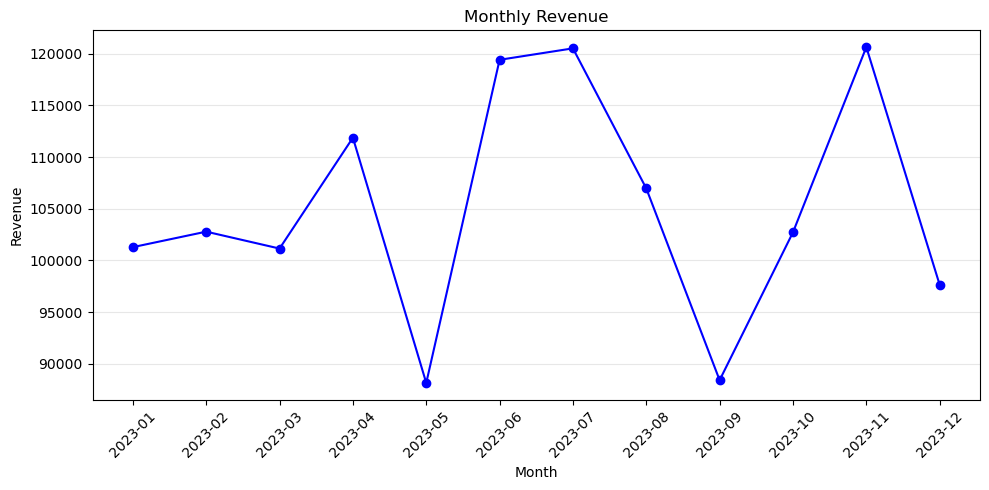

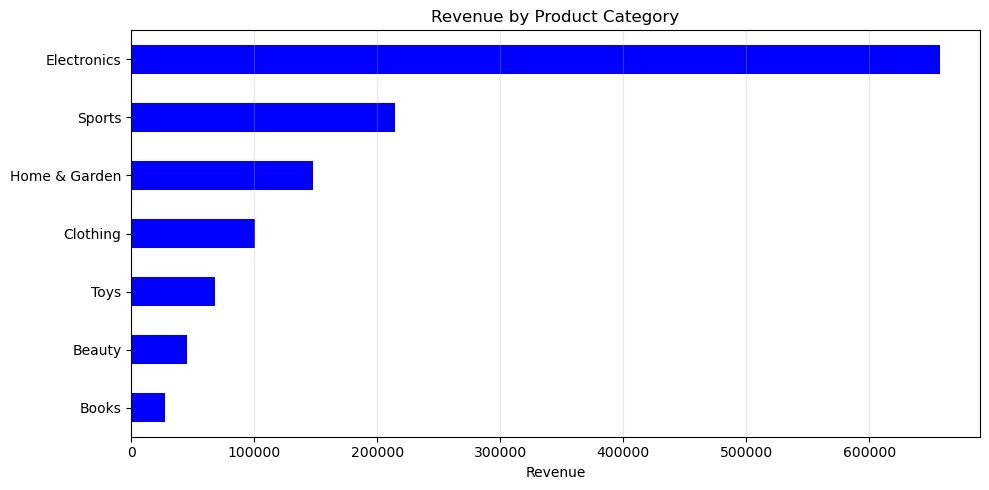

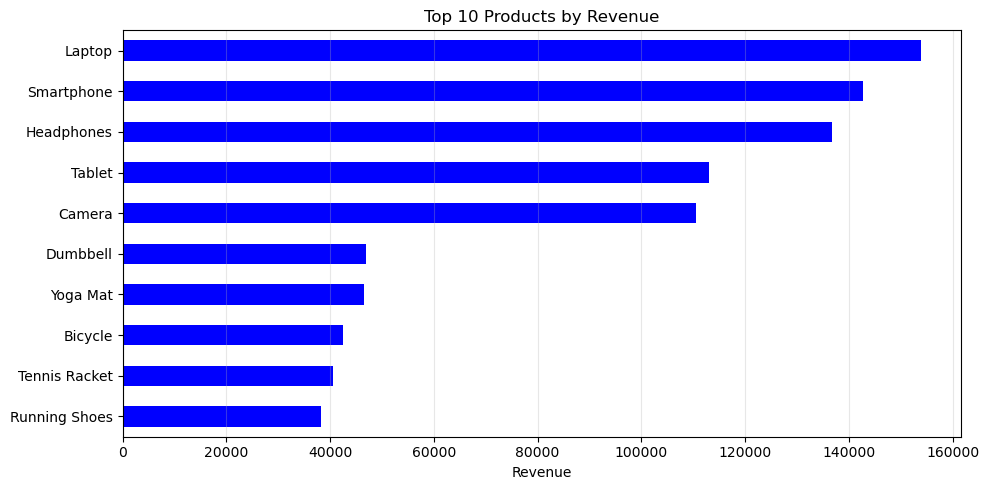

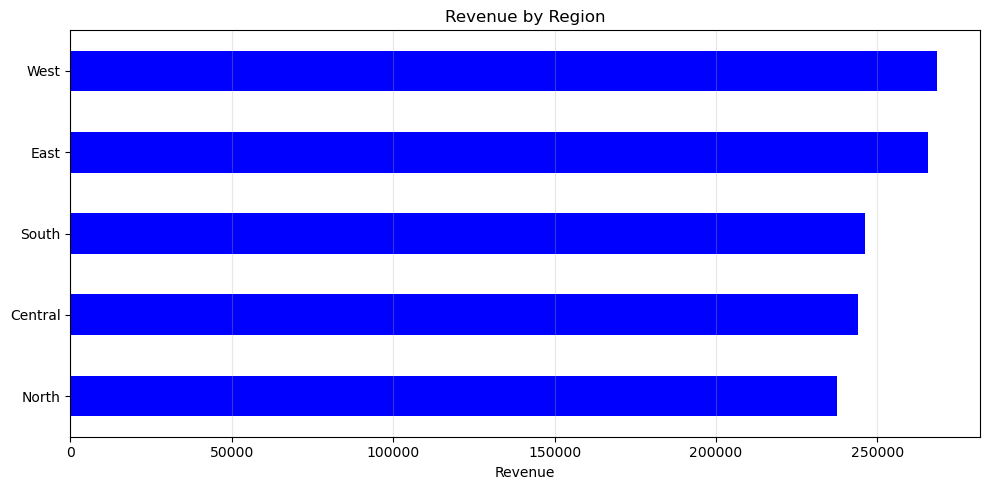

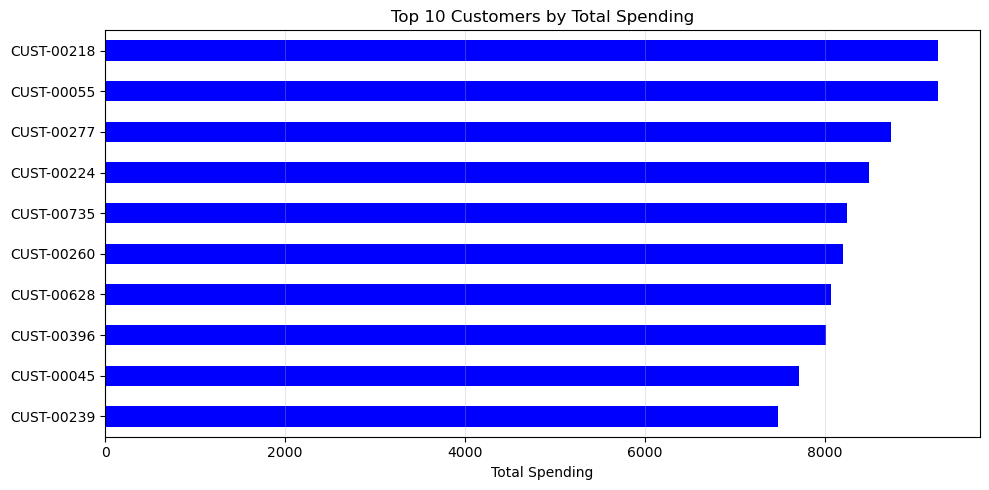

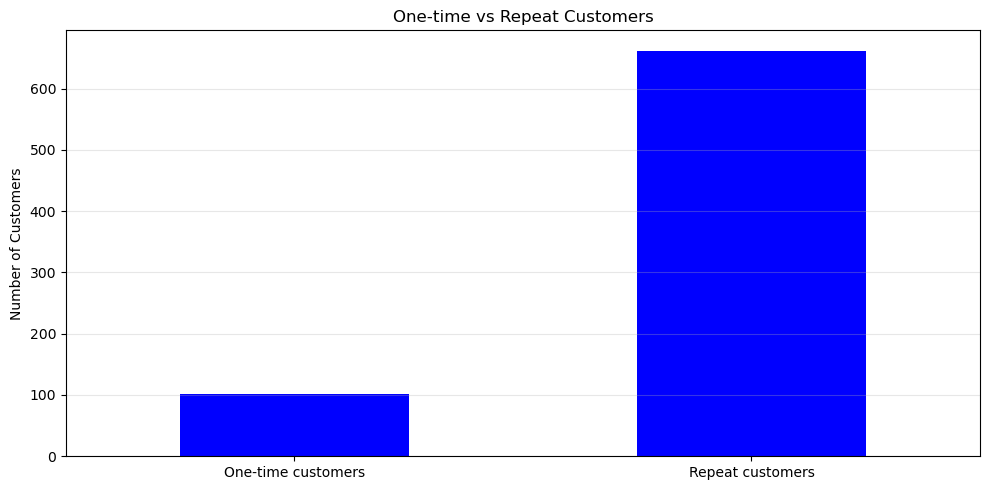

In [36]:
print("=== TASK 5: DATA VISUALIZATION ===")

# Những config thực sự cần thay đổi thường xuyên
FIGSIZE = (10, 5)
COLOR = 'blue'
TOP_N = 10
GRID_ALPHA = 0.3

# MONTHLY REVENUE TREND
plt.figure(figsize=FIGSIZE)

plt.plot(
    monthly_sales['order_month'].astype(str),
    monthly_sales['total_revenue'],
    color=COLOR,
    marker='o'
)

plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=GRID_ALPHA)
plt.tight_layout()

plt.show()

# REVENUE BY PRODUCT CATEGORY
category_sales.sort_values('total_revenue').plot.barh(
    x='product_category',
    y='total_revenue',
    figsize=FIGSIZE,
    color=COLOR,
    legend=False
)

plt.title('Revenue by Product Category')
plt.xlabel('Revenue')
plt.ylabel('')
plt.grid(axis='x', alpha=GRID_ALPHA)
plt.tight_layout()

plt.show()

# TOP PRODUCTS BY REVENUE
top_products = (
    product_performance
    .head(TOP_N)
    .sort_values('total_revenue')
)

top_products.plot.barh(
    x='product_name',
    y='total_revenue',
    figsize=FIGSIZE,
    color=COLOR,
    legend=False
)

plt.title(f'Top {TOP_N} Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('')
plt.grid(axis='x', alpha=GRID_ALPHA)
plt.tight_layout()

plt.show()

# REVENUE BY REGION
region_summary.sort_values('total_revenue').plot.barh(
    x='region',
    y='total_revenue',
    figsize=FIGSIZE,
    color=COLOR,
    legend=False
)

plt.title('Revenue by Region')
plt.xlabel('Revenue')
plt.ylabel('')
plt.grid(axis='x', alpha=GRID_ALPHA)
plt.tight_layout()

plt.show()

# TOP CUSTOMERS BY TOTAL SPENT
top_customers = (
    customer_summary
    .head(TOP_N)
    .sort_values('total_spent')
)

top_customers.plot.barh(
    x='customer_id',
    y='total_spent',
    figsize=FIGSIZE,
    color=COLOR,
    legend=False
)

plt.title(f'Top {TOP_N} Customers by Total Spending')
plt.xlabel('Total Spending')
plt.ylabel('')
plt.grid(axis='x', alpha=GRID_ALPHA)
plt.tight_layout()

plt.show()

# ONE-TIME AND REPEAT CUSTOMERS
customer_types = pd.Series({
    'One-time customers': (
        customer_summary['total_orders'] == 1
    ).sum(),

    'Repeat customers': (
        customer_summary['total_orders'] > 1
    ).sum()
})

customer_types.plot.bar(
    figsize=FIGSIZE,
    color=COLOR,
    rot=0
)

plt.title('One-time vs Repeat Customers')
plt.xlabel('')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=GRID_ALPHA)
plt.tight_layout()

plt.show()



### Task 6: Summary Report

Let's generate a comprehensive business report with key metrics and actionable insights.

In [37]:
print("=== TASK 6: SUMMARY REPORT ===")

# Lấy dòng có kết quả cao nhất từ các bảng phân tích trước
top_category = category_sales.iloc[0]
top_product = product_performance.iloc[0]
top_region = region_summary.iloc[0]

best_month = monthly_sales.loc[
    monthly_sales['total_revenue'].idxmax()
]

# Tính tỷ trọng doanh thu từ top 10 khách hàng
top_10_customer_share = (
    customer_summary.head(10)['total_spent'].sum()
    / total_revenue
    * 100
)

# Tạo báo cáo tổng hợp
summary_report = pd.DataFrame({
    'Metric': [
        'Total Revenue',
        'Total Orders',
        'Total Units Sold',
        'Average Order Value',
        'Top Product Category',
        'Top Product',
        'Best Revenue Month',
        'Top Region',
        'Repeat Customer Rate',
        'Top 10 Customer Revenue Share'
    ],
    'Value': [
        f'${total_revenue:,.2f}',
        f'{total_orders:,}',
        f'{total_units:,}',
        f'${average_order_value:,.2f}',
        (
            f"{top_category['product_category']} "
            f"(${top_category['total_revenue']:,.2f})"
        ),
        (
            f"{top_product['product_name']} "
            f"(${top_product['total_revenue']:,.2f})"
        ),
        (
            f"{best_month['order_month']} "
            f"(${best_month['total_revenue']:,.2f})"
        ),
        (
            f"{top_region['region']} "
            f"(${top_region['total_revenue']:,.2f})"
        ),
        f'{repeat_customer_rate:.2f}%',
        f'{top_10_customer_share:.2f}%'
    ]
})

display(summary_report)


=== TASK 6: SUMMARY REPORT ===


,Metric,Value
0,Total Revenue,"$1,261,554.02"
1,Total Orders,"2,500"
2,Total Units Sold,"6,096"
3,Average Order Value,$504.62
4,Top Product Category,"Electronics ($657,136.57)"
5,Top Product,"Laptop ($153,964.37)"
6,Best Revenue Month,"2023-11 ($120,651.01)"
7,Top Region,"West ($268,346.03)"
8,Repeat Customer Rate,86.65%
9,Top 10 Customer Revenue Share,6.62%


## Business Insights and Recommendations

Based on our comprehensive analysis, here are the key findings and strategic recommendations.

In [40]:
print("=== PRODUCT DEMAND BY REGION ===")

# Tổng sales volume của từng region
region_unit_share = (
    df.groupby('region')['quantity'].sum()
    / df['quantity'].sum()
)

# Tổng hợp kết quả của từng product tại từng region
product_region = (
    df.groupby(
        ['product_name', 'region'],
        as_index=False
    )
    .agg(
        units_sold=('quantity', 'sum'),
        total_revenue=('total_amount', 'sum'),
        total_orders=('order_id', 'nunique')
    )
)

# Tổng units của từng product trên tất cả region
product_region['product_total_units'] = (
    product_region
    .groupby('product_name')['units_sold']
    .transform('sum')
)

# Tỷ trọng lượng bán của product tại region
product_region['product_region_share'] = (
    product_region['units_sold']
    / product_region['product_total_units']
)

# Tỷ trọng sales volume chung của region
product_region['region_unit_share'] = (
    product_region['region']
    .map(region_unit_share)
)

# So sánh demand của product với quy mô chung của region
product_region['demand_index'] = (
    product_region['product_region_share']
    / product_region['region_unit_share']
)

allocation_insights = []

top_products = product_performance.head(5)[
    'product_name'
]

for product in top_products:

    product_data = product_region[
        product_region['product_name'] == product
    ]

    # Region có demand index cao nhất
    strongest_region = product_data.loc[
        product_data['demand_index'].idxmax()
    ]

    # Region có demand index thấp nhất
    weakest_region = product_data.loc[
        product_data['demand_index'].idxmin()
    ]

    allocation_insights.append({
        'product_name': product,

        'priority_region': strongest_region['region'],
        'priority_units': strongest_region['units_sold'],
        'priority_demand_index': strongest_region['demand_index'],

        'review_region': weakest_region['region'],
        'review_units': weakest_region['units_sold'],
        'review_demand_index': weakest_region['demand_index']
    })

allocation_insights = pd.DataFrame(
    allocation_insights
)

display(
    allocation_insights.round({
        'priority_demand_index': 2,
        'review_demand_index': 2
    })
)


=== PRODUCT DEMAND BY REGION ===


,product_name,priority_region,priority_units,priority_demand_index,review_region,review_units,review_demand_index
0,Laptop,East,58,1.65,South,22,0.59
1,Smartphone,South,63,1.57,North,26,0.62
2,Headphones,East,42,1.18,South,31,0.82
3,Tablet,North,35,1.13,Central,21,0.69
4,Camera,South,55,1.91,North,16,0.53


## Additional Analysis

Let's perform some additional analysis to gain deeper insights into customer behavior.

In [42]:
print("=== ADDITIONAL ANALYSIS: CUSTOMER RETENTION VALUE ===")

# Phân loại khách hàng dựa trên số order
customer_summary['customer_type'] = np.where(
    customer_summary['total_orders'] > 1,
    'Repeat',
    'One-time'
)

# So sánh giá trị của khách mua một lần và khách quay lại
customer_type_summary = (
    customer_summary
    .groupby('customer_type', as_index=False)
    .agg(
        customers=('customer_id', 'nunique'),
        total_revenue=('total_spent', 'sum'),
        average_customer_value=('total_spent', 'mean'),
        average_orders=('total_orders', 'mean')
    )
)

# Tỷ trọng doanh thu của từng nhóm khách hàng
customer_type_summary['revenue_share_pct'] = (
    customer_type_summary['total_revenue']
    / total_revenue
    * 100
)

display(
    customer_type_summary.round({
        'total_revenue': 2,
        'average_customer_value': 2,
        'average_orders': 2,
        'revenue_share_pct': 2
    })
)


=== ADDITIONAL ANALYSIS: CUSTOMER RETENTION VALUE ===


,customer_type,customers,total_revenue,average_customer_value,average_orders,revenue_share_pct
0,One-time,102,36084.96,353.77,1.00,2.86
1,Repeat,662,1225469.06,1851.16,3.62,97.14


In [43]:
one_time_customer = customer_type_summary.loc[
    customer_type_summary['customer_type'] == 'One-time'
].iloc[0]

repeat_customer = customer_type_summary.loc[
    customer_type_summary['customer_type'] == 'Repeat'
].iloc[0]

customer_value_multiplier = (
    repeat_customer['average_customer_value']
    / one_time_customer['average_customer_value']
)

print(
    f"Repeat customers có giá trị trung bình cao gấp "
    f"{customer_value_multiplier:.2f} lần one-time customers."
)


Repeat customers có giá trị trung bình cao gấp 5.23 lần one-time customers.
